# RANDOM FOREST - 50 POHON (GINI)

### Deskripsi Teori & Varian:
* **Algoritma**: Random Forest (Gini)
* **Varian**: Jumlah Pohon Lebih Sedikit (n_estimators = 50)
* **Konsep**: Mengurangi jumlah pohon keputusan dari 100 menjadi 50. Varian ini diuji untuk melihat efisiensi komputasi (apakah model tetap akurat meskipun hanya menggunakan setengah dari jumlah pohon standar?). Jika akurasi tetap tinggi, model ini bisa menjadi pilihan yang lebih ringan untuk *deployment*.

In [1]:
import time
import tracemalloc
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

df_hoaks = pd.read_csv('../data/komdigi_hoaks.csv')
df_valid = pd.read_csv('../web/uploads/berita_valid_terbaru.csv')

def clean_text(text):
    if not isinstance(text, str): return ''
    text = re.sub(r'\[(HOAKS|DISINFORMASI|MISINFORMASI|KLARIFIKASI|SALAH|FALSE)\]', '', text, flags=re.IGNORECASE)
    text = re.sub(r'\((HOAKS|DISINFORMASI|MISINFORMASI|KLARIFIKASI|SALAH|FALSE)\)', '', text, flags=re.IGNORECASE)
    text = re.sub(r'https?:\/\/\S+|www\.\S+', '', text)
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    return re.sub(r'\s+', ' ', text.lower()).strip()

df_hoaks['teks_bersih'] = (df_hoaks['title'].fillna('') + ' ' + df_hoaks['excerpt'].fillna('')).apply(clean_text)
df_valid['teks_bersih'] = (df_valid['title'].fillna('') + ' ' + df_valid['excerpt'].fillna('')).apply(clean_text)

df_hoaks['label'] = 1
df_valid['label'] = 0

df_hoaks_sampel = df_hoaks.sample(n=len(df_valid), random_state=42)
df_all = pd.concat([df_hoaks_sampel, df_valid], ignore_index=True)
df_all = df_all[df_all['teks_bersih'].str.len() > 10].reset_index(drop=True)

X_train, X_test, y_train, y_test = train_test_split(
    df_all['teks_bersih'], df_all['label'], test_size=0.2, random_state=42, stratify=df_all['label']
)
tfidf = TfidfVectorizer(max_features=1500, ngram_range=(1, 2))
X_train_vec = tfidf.fit_transform(X_train)
X_test_vec = tfidf.transform(X_test)

print("Preprocessing Selesai!")

Preprocessing Selesai!


In [2]:
tracemalloc.start()
waktu_mulai = time.time()

# Model Random Forest - 50 Pohon
model = RandomForestClassifier(n_estimators=50, criterion='gini', max_depth=None, random_state=42)
model.fit(X_train_vec, y_train)
y_pred = model.predict(X_test_vec)

waktu_eksekusi = time.time() - waktu_mulai
current_mem, peak_mem = tracemalloc.get_traced_memory()
tracemalloc.stop()
memori_mb = peak_mem / (1024 * 1024)

acc = accuracy_score(y_test, y_pred)
prec_macro = precision_score(y_test, y_pred, average='macro', zero_division=0)
rec_macro = recall_score(y_test, y_pred, average='macro', zero_division=0)
f1_macro = f1_score(y_test, y_pred, average='macro', zero_division=0)
f1_weighted = f1_score(y_test, y_pred, average='weighted', zero_division=0)

print("=============================================")
print("HASIL PENGUJIAN: RANDOM FOREST - 50 POHON")
print("=============================================")
print(f"1. Algoritma        : Random Forest")
print(f"2. Metrik Jarak     : Gini Impurity (50 Pohon)")
print(f"3. Akurasi          : {acc:.4f}")
print(f"4. Precision (Macro): {prec_macro:.4f}")
print(f"5. Recall (Macro)   : {rec_macro:.4f}")
print(f"6. F1-Score (Macro) : {f1_macro:.4f}")
print(f"7. F1-Score (Weighted): {f1_weighted:.4f}")
print(f"8. Waktu Eksekusi   : {waktu_eksekusi:.4f} detik")
print(f"9. Penggunaan Memori: {memori_mb:.2f} MB")
print("=============================================\n")

print("Laporan Klasifikasi Detail:")
print(classification_report(y_test, y_pred, target_names=['Valid (0)', 'Hoaks (1)'], zero_division=0))

HASIL PENGUJIAN: RANDOM FOREST - 50 POHON
1. Algoritma        : Random Forest
2. Metrik Jarak     : Gini Impurity (50 Pohon)
3. Akurasi          : 0.8867
4. Precision (Macro): 0.8892
5. Recall (Macro)   : 0.8867
6. F1-Score (Macro) : 0.8865
7. F1-Score (Weighted): 0.8865
8. Waktu Eksekusi   : 0.5459 detik
9. Penggunaan Memori: 0.37 MB

Laporan Klasifikasi Detail:
              precision    recall  f1-score   support

   Valid (0)       0.92      0.85      0.88       150
   Hoaks (1)       0.86      0.93      0.89       150

    accuracy                           0.89       300
   macro avg       0.89      0.89      0.89       300
weighted avg       0.89      0.89      0.89       300



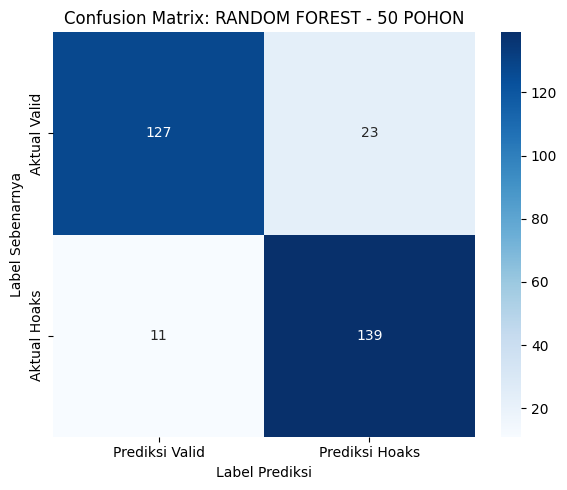

In [3]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Prediksi Valid', 'Prediksi Hoaks'],
            yticklabels=['Aktual Valid', 'Aktual Hoaks'])
plt.title('Confusion Matrix: RANDOM FOREST - 50 POHON')
plt.ylabel('Label Sebenarnya')
plt.xlabel('Label Prediksi')
plt.tight_layout()
plt.show()

### Pembahasan Akademis: Random Forest (50 Pohon)

1. **Analisis Performa & Akurasi**:
   * Model Random Forest dengan 50 pohon menghasilkan akurasi sebesar **88.67%** dengan F1-Score 0.8865.
   * Terjadi penurunan akurasi sebesar 2.66% dibandingkan model 100 pohon (91.33%). Hal ini membuktikan bahwa 50 pohon belum cukup untuk menstabilkan hasil *voting* (suara mayoritas). Dengan pohon yang lebih sedikit, varians (noise) dari masing-masing pohon masih cukup besar, sehingga menurunkan akurasi keseluruhan.

2. **Efisiensi Komputasi (Trade-off)**:
   * Waktu eksekusi turun drastis menjadi **0.5459 detik** (paling cepat di antara seluruh varian Random Forest). Penggunaan memori juga paling ringan (0.37 MB).
   * Ini adalah bentuk *trade-off* klasik: kita menghemat waktu komputasi hampir 50%, namun harus rela kehilangan akurasi sekitar 2.6%. Untuk sistem *real-time* dengan sumber daya terbatas, kompromi ini bisa diterima, namun untuk akurasi maksimal, 100 pohon tetap lebih direkomendasikan.

3. **Kesimpulan Hyperparameter Tuning**:
   * Eksperimen ini menegaskan bahwa `n_estimators=100` adalah titik optimal (*sweet spot*) untuk dataset ini. Di bawah 100, akurasi turun (underfitting). Di atas 100, akurasi tidak naik signifikan namun waktu komputasi melonjak.